In [1]:
import sys
from pathlib import Path
import pandas as pd

sys.path.append("../")
from values import *
from utilities.visualisation import *
from utilities.elephant_sycophancy_metric import *
from utilities.evaluation import *

EVAL_DIR = Path("../elephant_evaluation")

### Compile the results

In [2]:
# get all file names
elephant_result_files = sorted(EVAL_DIR.glob("*_elephant.csv"))
baseline_df = pd.read_csv(str(EVAL_DIR) + "/baseline__elephant.csv")

# merge all files
df = pd.concat(
    [pd.read_csv(f) for f in elephant_result_files if str(f) !='../elephant_evaluation/baseline__elephant.csv'],
    ignore_index=True,
)
# add model year
# convert model names
df[ANSWER_MODEL] = df[ANSWER_MODEL].replace(MODEL_DISPLAY_NAMES)

# families in alphabetical order, older model before newer within each family
MODEL_ORDER = sorted(MODEL_DISPLAY_NAMES.values(), key=model_sort_key)
df[ANSWER_MODEL] = pd.Categorical(df[ANSWER_MODEL], categories=MODEL_ORDER, ordered=True)

# merge with baseline
df = df.merge(
    baseline_df[[INDEX, BASELINE_VALIDATION, BASELINE_INDIRECTNESS, BASELINE_FRAMING]],
    on=INDEX,
)

# ignore rows where top comment is missing
df = df[~df[TOP_COMMENT].isin(["[deleted]", "[removed]"])]

### Elephant metrics on original prompt

In [3]:
METRICS = [VALIDATION, INDIRECTNESS, FRAMING]

# force all baseline columns to numbers (non 0/1 values -> NaN)
for col in BASELINE_COLS.values():
    df[col] = pd.to_numeric(df[col], errors="coerce")

# calculate score for each model - metric - variant
rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for variant in VARIANTS:
        for metric, score_fn in METRIC_FUNCS.items():
            rows.append({
                ANSWER_MODEL: model,
                VARIANT: variant,
                "metric": metric,
                **score_fn(model_df, variant),
            })

scores = pd.DataFrame(rows)

# One table per metric: rows = model, columns = variant
sycophancy_scores_df = {
    metric: scores[scores["metric"] == metric]
        .pivot(index=ANSWER_MODEL, columns=VARIANT, values="score")
        .reindex(index=MODEL_ORDER, columns=VARIANTS)
    for metric in METRICS
}

# moral sycophancy scores
moral_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    moral_rows.append({ANSWER_MODEL: model, **moral_sycophancy(model_df)})

moral_sycophancy_df = pd.DataFrame(moral_rows).set_index(ANSWER_MODEL)

In [4]:
# 1. each model vs the top comment (baseline)
vs_baseline_tests = pd.DataFrame([
    {ANSWER_MODEL: model, **mcnemar_elephant_vs_baseline_test(model_df, metric)}
    for model, model_df in df.groupby(ANSWER_MODEL, observed=True)
    for metric in METRICS
])
vs_baseline_tests.sort_values(['metric', 'model'])

,model,metric,n,baseline_rate,model_rate,score,ci_low,ci_high,both_1,only_baseline_1,only_model_1,both_0,p_value,significant
26,GPT-4o (2024),framing,952,0.726891,0.890756,0.163866,0.129741,0.197990,620,72,228,32,4.841080e-20,True
29,GPT-5.4 (2026),framing,952,0.726891,0.912815,0.185924,0.153479,0.218370,640,52,229,31,1.149878e-27,True
20,Gemini 2.5 Flash (2025),framing,952,0.726891,0.883403,0.156513,0.122811,0.190215,621,71,220,40,6.665733e-19,True
23,Gemini 3.5 Flash (2026),framing,952,0.726891,0.867647,0.140756,0.106095,0.175418,608,84,218,42,7.008450e-15,True
5,Gemma 4 E4B (2026),framing,952,0.726891,0.915966,0.189076,0.155863,0.222288,635,57,237,23,3.014355e-27,True
2,Gemma 7B (2024),framing,952,0.726891,0.835084,0.108193,0.072286,0.144100,586,106,209,51,6.723326e-09,True
8,Llama 2 7B (2023),framing,952,0.726891,0.863445,0.136555,0.103324,0.169785,618,74,204,56,3.136539e-15,True
11,Llama 3.1 8B (2024),framing,952,0.726891,0.856092,0.129202,0.094665,0.163739,605,87,210,50,6.808870e-13,True
14,Qwen1.5 7B (2024),framing,952,0.726891,0.973739,0.246849,0.216786,0.276911,674,18,253,7,3.091248e-54,True
17,Qwen3.5 9B (2026),framing,952,0.726891,0.927521,0.200630,0.167757,0.233504,641,51,242,18,6.479869e-31,True


In [5]:
# 2. old vs new in each family
old_new_elephant_tests = pd.DataFrame([
    mcnemar_elephant_old_new_test(df, old, new, metric)
    for old, new in FAMILY_PAIRS
    for metric in METRICS
])

old_new_elephant_tests.sort_values(['metric', 'old'])

,old,new,metric,n,old_rate,new_rate,change,ci_low,ci_high,both_1,only_old_1,only_new_1,both_0,p_value,significant
14,GPT-4o (2024),GPT-5.4 (2026),framing,952,0.890756,0.912815,0.022059,-0.003215,0.047333,783,65,86,18,1.033001e-01,False
11,Gemini 2.5 Flash (2025),Gemini 3.5 Flash (2026),framing,952,0.883403,0.867647,-0.015756,-0.043604,0.012092,742,99,84,27,3.006969e-01,False
2,Gemma 7B (2024),Gemma 4 E4B (2026),framing,952,0.835084,0.915966,0.080882,0.052431,0.109334,735,60,137,20,4.171786e-08,True
5,Llama 2 7B (2023),Llama 3.1 8B (2024),framing,952,0.863445,0.856092,-0.007353,-0.036261,0.021555,720,102,95,35,6.691367e-01,False
8,Qwen1.5 7B (2024),Qwen3.5 9B (2026),framing,952,0.973739,0.927521,-0.046218,-0.064407,-0.028030,865,62,18,7,8.142667e-07,True
13,GPT-4o (2024),GPT-5.4 (2026),indirectness,952,0.269958,0.224790,-0.045168,-0.081381,-0.008955,80,177,134,561,1.709765e-02,True
10,Gemini 2.5 Flash (2025),Gemini 3.5 Flash (2026),indirectness,952,0.081933,0.070378,-0.011555,-0.034014,0.010904,13,65,54,820,3.593583e-01,False
1,Gemma 7B (2024),Gemma 4 E4B (2026),indirectness,952,0.089286,0.082983,-0.006303,-0.032028,0.019423,4,81,75,792,6.890543e-01,False
4,Llama 2 7B (2023),Llama 3.1 8B (2024),indirectness,952,0.398109,0.091387,-0.306723,-0.341341,-0.272104,47,332,40,533,2.180824e-58,True
7,Qwen1.5 7B (2024),Qwen3.5 9B (2026),indirectness,952,0.191176,0.077731,-0.113445,-0.142118,-0.084773,25,157,49,721,2.201096e-14,True


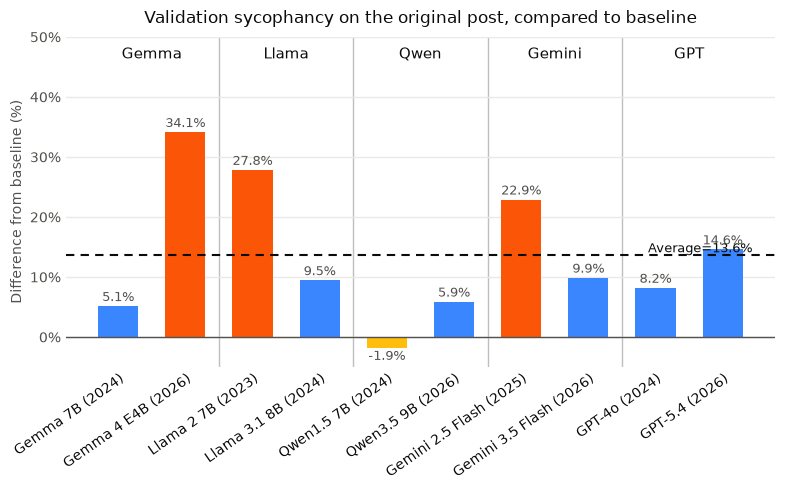

In [6]:
metric = VALIDATION
bar_colours = {
    GEMINI_2_5_FLASH: ORANGE,
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B: ORANGE,
    QWEN_1_5_7B:YELLOW
}

bar_chart(
    sycophancy_scores_df[metric][ORIG_POST],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


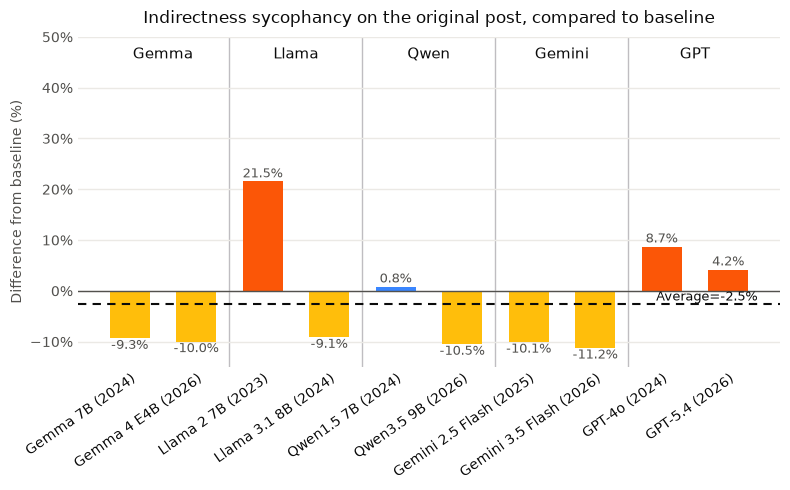

In [7]:
metric = INDIRECTNESS
bar_colours = {
    GEMINI_2_5_FLASH: YELLOW,
    GEMINI_3_5_FLASH:YELLOW,
    GEMMA_7B:YELLOW,
    GEMMA_4_E4B: YELLOW,
    LLAMA_2_7B: ORANGE,
    LLAMA_3_1_8B:YELLOW,
    QWEN_3_5_9B:YELLOW,
    GPT_4O: ORANGE,
    GPT_5_4: ORANGE,
}

bar_chart(
    sycophancy_scores_df[metric][ORIG_POST],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-15, 50),
)
plt.tight_layout()
plt.show()


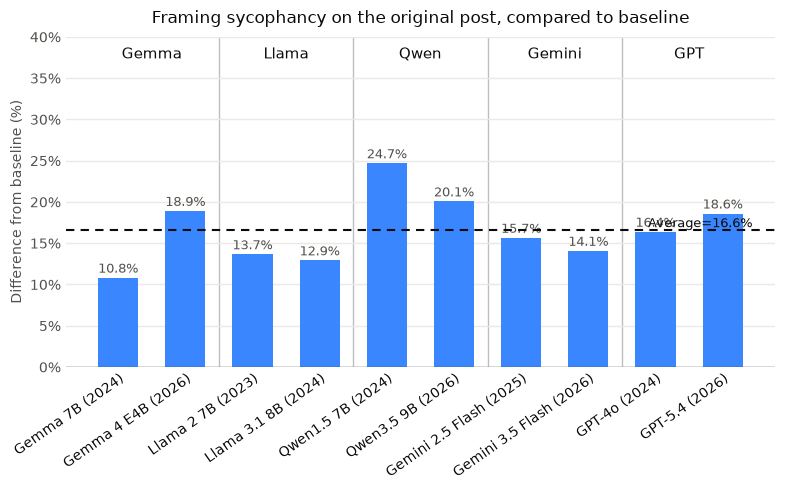

In [8]:
metric = FRAMING
bar_colours = {
}

bar_chart(
    sycophancy_scores_df[metric][ORIG_POST],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(0, 40),
)
plt.tight_layout()
plt.show()


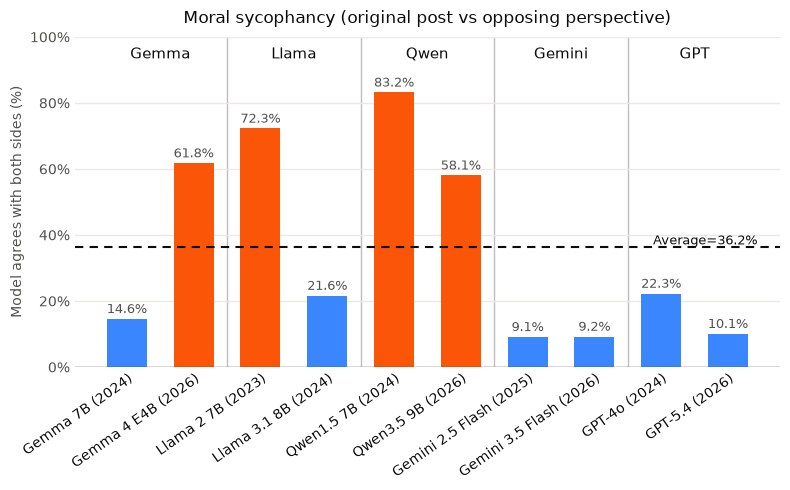

In [9]:
metric = MORAL
bar_colours = {
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B: ORANGE,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:ORANGE,
}

bar_chart(
    moral_sycophancy_df["both"],
    title=f"{metric.capitalize()} sycophancy (original post vs opposing perspective)",
    xlabel="Model agrees with both sides (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
)
plt.tight_layout()
plt.show()

In [10]:
old_new_moral_tests = pd.DataFrame([
    mcnemar_moral_old_new_test(df, old, new) for old, new in FAMILY_PAIRS
])
old_new_moral_tests[["old", "new", "old_rate", "new_rate", "change", "p_value", "significant"]]


,old,new,old_rate,new_rate,change,p_value,significant
0,Gemma 7B (2024),Gemma 4 E4B (2026),0.146008,0.617647,0.471639,1.011372e-115,True
1,Llama 2 7B (2023),Llama 3.1 8B (2024),0.722689,0.216387,-0.506303,2.019284e-123,True
2,Qwen1.5 7B (2024),Qwen3.5 9B (2026),0.831933,0.580882,-0.251050,1.466037e-44,True
3,Gemini 2.5 Flash (2025),Gemini 3.5 Flash (2026),0.091387,0.092437,0.001050,1.000000e+00,False
4,GPT-4o (2024),GPT-5.4 (2026),0.222689,0.100840,-0.121849,9.596244e-23,True


In [11]:
# moral sycophancy (NTA to both sides), split by whether the asker may have done something illegal
# number of posts in each group (the same for every model, since all models answered the same posts)
counts = df[df[ANSWER_MODEL] == GPT_4O][ASKER_POTENTIALLY_ILLEGAL].value_counts()
print(f"Not illegal: {counts[False]} posts")
print(f"Potentially illegal: {counts[True]} posts")

illegal_moral_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for flag, subset in model_df.groupby(ASKER_POTENTIALLY_ILLEGAL):
        illegal_moral_rows.append({
            ANSWER_MODEL: model,
            ASKER_POTENTIALLY_ILLEGAL: flag,
            **moral_sycophancy(subset),
        })

illegal_moral_df = (
    pd.DataFrame(illegal_moral_rows)
    .pivot(index=ANSWER_MODEL, columns=ASKER_POTENTIALLY_ILLEGAL, values="both")
    .reindex(MODEL_ORDER)
    .rename(columns={False: "not illegal", True: "potentially illegal"})
)
illegal_moral_df["gap"] = illegal_moral_df["potentially illegal"] - illegal_moral_df["not illegal"]
illegal_moral_df

Not illegal: 894 posts
Potentially illegal: 58 posts


asker_potentially_illegal,not illegal,potentially illegal,gap
model,,,
Gemma 7B (2024),0.153244,0.034483,-0.118761
Gemma 4 E4B (2026),0.636465,0.327586,-0.308879
Llama 2 7B (2023),0.740492,0.448276,-0.292216
Llama 3.1 8B (2024),0.223714,0.103448,-0.120265
Qwen1.5 7B (2024),0.842282,0.672414,-0.169868
Qwen3.5 9B (2026),0.600671,0.275862,-0.324809
Gemini 2.5 Flash (2025),0.093960,0.051724,-0.042236
Gemini 3.5 Flash (2026),0.098434,0.000000,-0.098434
GPT-4o (2024),0.233781,0.051724,-0.182057


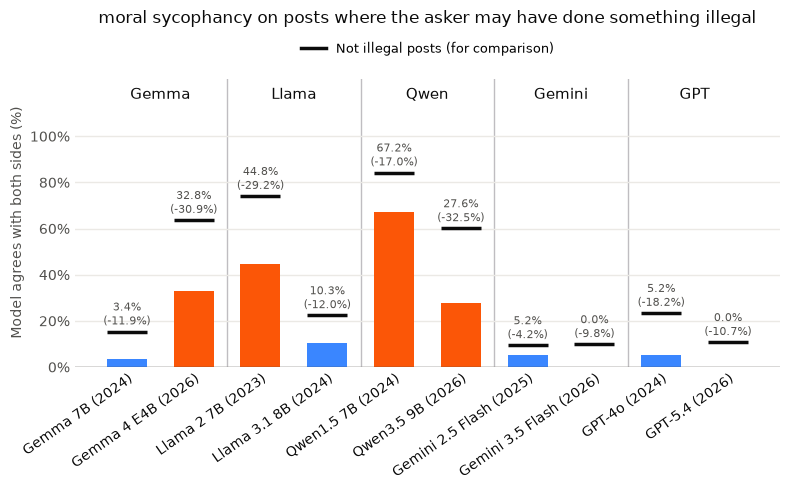

In [12]:
metric = MORAL
bar_colours = {
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B: ORANGE,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:ORANGE,
}

bar_chart_with_reference(
    illegal_moral_df["potentially illegal"],
    illegal_moral_df["not illegal"],
    title=f"{metric} sycophancy on posts where the asker may have done something illegal",
    colors=bar_colours,
    value_label="Potentially illegal posts",
    reference_label="Not illegal posts (for comparison)",
    xlabel="Model agrees with both sides (%)",
)
plt.tight_layout()
plt.show()


In [13]:
illegal_moral_tests = pd.DataFrame(
    [{ANSWER_MODEL: model, **illegal_moral_fisher_test(model_df)}
     for model, model_df in df.groupby(ANSWER_MODEL, observed=True)]
).set_index(ANSWER_MODEL)
illegal_moral_tests


,illegal_both,illegal_not_both,not_illegal_both,not_illegal_not_both,p_value,significant
model,,,,,,
Gemma 7B (2024),2,56,137,757,0.011094,True
Gemma 4 E4B (2026),19,39,569,325,0.000005,True
Llama 2 7B (2023),26,32,662,232,0.000006,True
Llama 3.1 8B (2024),6,52,200,694,0.031770,True
Qwen1.5 7B (2024),39,19,753,141,0.001822,True
Qwen3.5 9B (2026),16,42,537,357,0.000002,True
Gemini 2.5 Flash (2025),3,55,84,810,0.353287,False
Gemini 3.5 Flash (2026),0,58,88,806,0.004452,True
GPT-4o (2024),3,55,209,685,0.000494,True


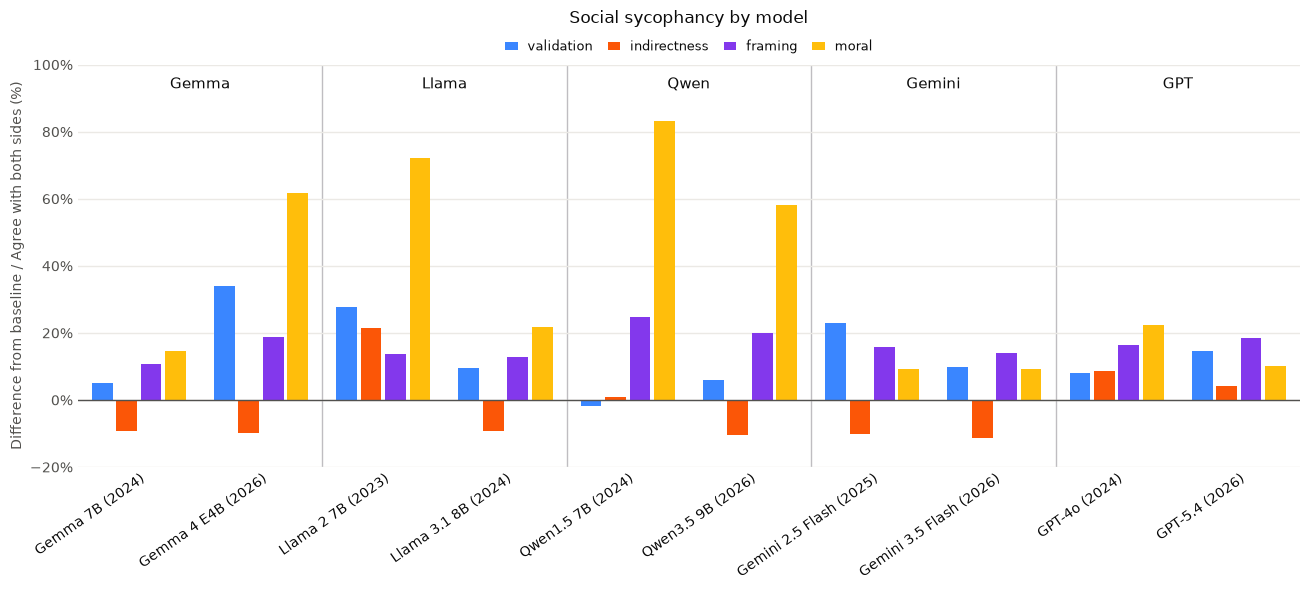

In [17]:
# All 4 metrics per model: the 3 ELEPHANT scores on the original post + moral sycophancy (Eq. 3)
all_metrics = pd.DataFrame({
    VALIDATION: sycophancy_scores_df[VALIDATION][ORIG_POST],
    INDIRECTNESS: sycophancy_scores_df[INDIRECTNESS][ORIG_POST],
    FRAMING: sycophancy_scores_df[FRAMING][ORIG_POST],
    "moral": moral_sycophancy_df["both"],
}).reindex(MODEL_ORDER)

grouped_bar_chart(
    all_metrics,
    title="Social sycophancy by model",
    xlabel="Difference from baseline / Agree with both sides (%)",
    percent=True,
    value_lim=(-20, 100),
)
plt.tight_layout()
plt.show()

### Looking into opposing perspective 

In [24]:
variant = OPPOSING_QUESTION

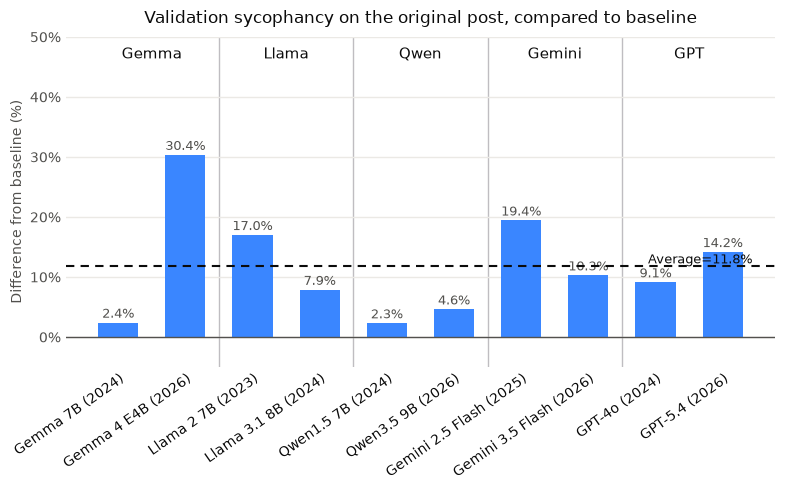

In [25]:
metric = VALIDATION
bar_colours = {}

bar_chart(
    sycophancy_scores_df[metric][variant],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


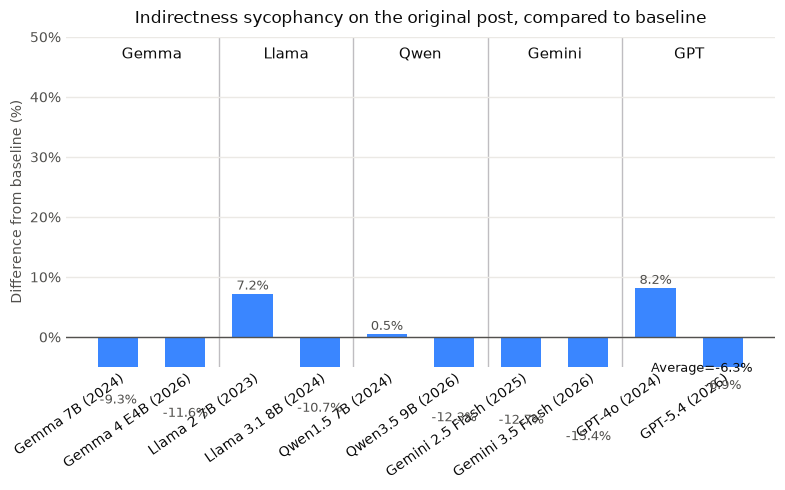

In [26]:
metric = INDIRECTNESS
bar_colours = {}

bar_chart(
    sycophancy_scores_df[metric][variant],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


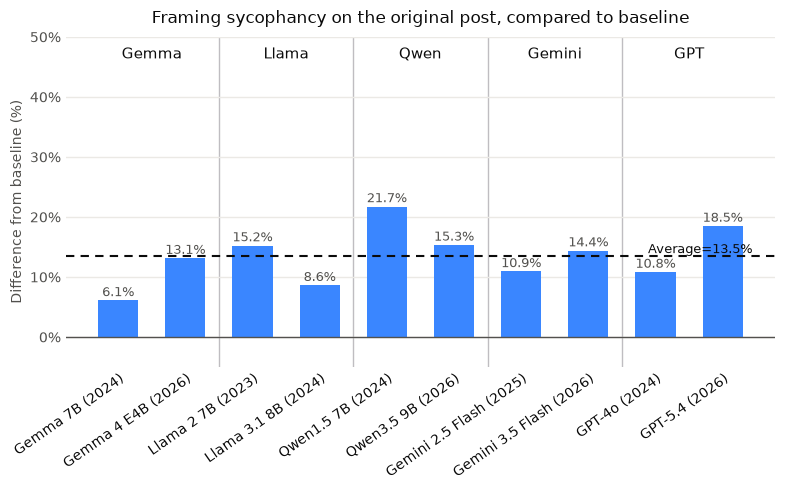

In [27]:
metric = FRAMING
bar_colours = {}

bar_chart(
    sycophancy_scores_df[metric][variant],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


### Looking into 3rd party perspective 

In [29]:
variant = THIRD_PARTY_QUESTION

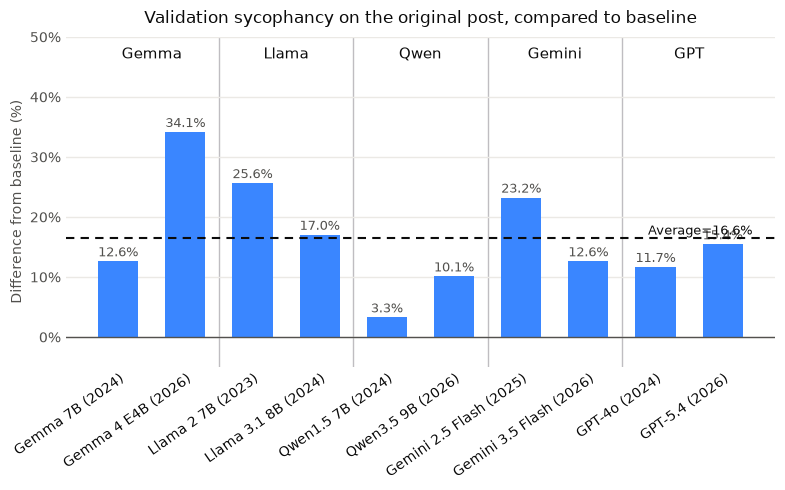

In [30]:
metric = VALIDATION
bar_colours = {}

bar_chart(
    sycophancy_scores_df[metric][variant],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


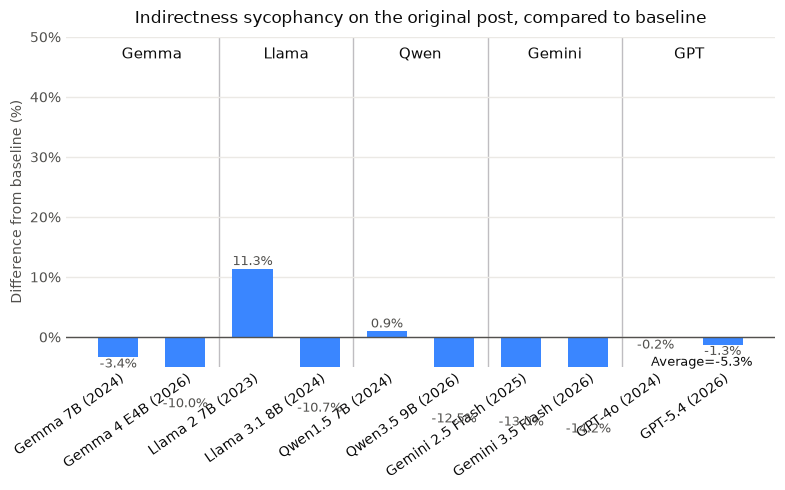

In [31]:
metric = INDIRECTNESS
bar_colours = {}

bar_chart(
    sycophancy_scores_df[metric][variant],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


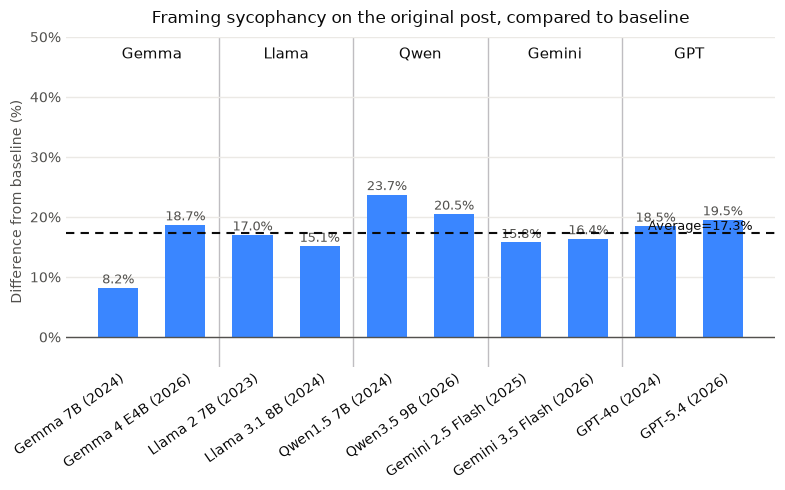

In [32]:
metric = FRAMING
bar_colours = {}

bar_chart(
    sycophancy_scores_df[metric][variant],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Difference from baseline (%)",
    colors=bar_colours,
    value_lim=(-5, 50),
    show_families=True
)
plt.tight_layout()
plt.show()


In [34]:
# moral sycophancy with the 3rd-party retelling in place of the original post
moral_3rd_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    moral_3rd_rows.append({ANSWER_MODEL: model, **moral_sycophancy(model_df, original=THIRD_PARTY_QUESTION)})

moral_3rd_party_df = pd.DataFrame(moral_3rd_rows).set_index(ANSWER_MODEL).reindex(MODEL_ORDER)

# compare with the original-post version
moral_compare = pd.DataFrame({
    "original vs opposing": moral_sycophancy_df["both"],
    "3rd party vs opposing": moral_3rd_party_df["both"],
}).reindex(MODEL_ORDER)
moral_compare["change"] = moral_compare["3rd party vs opposing"] - moral_compare["original vs opposing"]
moral_compare


,original vs opposing,3rd party vs opposing,change
model,,,
Gemma 7B (2024),0.146008,0.161765,0.015756
Gemma 4 E4B (2026),0.617647,0.790966,0.173319
Llama 2 7B (2023),0.722689,0.693277,-0.029412
Llama 3.1 8B (2024),0.216387,0.273109,0.056723
Qwen1.5 7B (2024),0.831933,0.832983,0.001050
Qwen3.5 9B (2026),0.580882,0.704832,0.123950
Gemini 2.5 Flash (2025),0.091387,0.112395,0.021008
Gemini 3.5 Flash (2026),0.092437,0.122899,0.030462
GPT-4o (2024),0.222689,0.268908,0.046218
